**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**10 | Temporal Architecture Engineering and Matched HARTH Development Benchmark**

![Temporal architecture and matched benchmark workflow](../../images/10_consolidated_workflow.svg)

**Objective:** Verify four advanced temporal architectures for six-channel HARTH activity windows and compare seven predeclared classifiers on identical participant-held-out Development observations. Keep the engineering smoke test and the full matched benchmark as separate evidence units within one notebook.

**Dataset:** Pinned official NTNU AI Lab HARTH v2.0 source recordings, six lower-back/thigh acceleration channels at nominal 50 Hz and eight documented activity codes (1–8). Both stages use 100-sample, label-pure, timestamp-continuous windows with a 50-sample stride. The engineering subset uses four Development participants; the benchmark uses all 29 Development participants with an independent label-blind maximum of 500 windows per person.

**Architecture engineering:** Validate TCN, Multi-Scale CNN, 1D-ResNet and Time-Series Transformer using input/output contracts, parameter counts, illustrative CPU timings, participant-disjoint source windows and a single optimiser update. Include Simple Temporal CNN as the engineering capacity reference.

**Matched benchmark:** Compare Random Forest, Standard CNN, Weighted CNN and the four advanced models across the same three GroupKFold splits (seven models × three folds). Preserve Train-only neural channel scaling and loss weights, a 400-Adam-update neural budget, the 120-tree Random Forest reference and the original eight-class Macro F1 definition. Source-row alignment, per-class and per-person results, and compute costs are reported separately.

**Execution and outputs:** Section 11 requires a CUDA GPU for the approved full benchmark; Sections 02–10 can be examined without fitting the full benchmark. Validated local model–fold caches may be reused. The complete run writes current `10_` CSV/PNG evidence under `wearable_activity_recognition/output/` and offers one final stage-specific ZIP.

**Scientific boundary:** Development-only offline window classification. Reserved participants S023/S032 are not loaded; overlapping windows are not independent individuals. Equal update counts are not equal computational budgets or causal evidence about architectures. This consolidated notebook does not perform final qualified Test evaluation, external validation or clinical deployment.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Standard Library ----------------------------
import time

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# -------------- 5. Machine Learning and Deep Learning Framework --------------
import torch
from torch import nn
from core.feature_engineering import extract_signal_features

# ----------- 6. HARTH Source, Architecture and Benchmark Utilities -----------
from core.output_download import download_outputs_from_colab
from harth_data import (
    HARTH_SUBJECTS, HARTH_REVISION, ACTIVITY_NAMES, SENSOR_COLUMNS,
    prepare_harth_window_cohort,
)
from core.advanced_temporal_models import (
    ARCHITECTURES, build_temporal_model, count_trainable_parameters,
)
from core.temporal_cnn import TemporalCNN, standardise_imu_train_only
from core.temporal_benchmark import (
    MODEL_NAMES, PROTOCOL_VERSION, make_benchmark_plan,
    run_benchmark_job, summarise_benchmark_results,
)

# ------------------ 7. Reproducibility and Device Selection ------------------
from core.computer_device import computer_device

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = computer_device()
DEVICE = device.type

# -------------------- 8. Task and Current Output Settings --------------------
CLASSES = tuple(range(1, 9))
RESERVED_TEST = {"S023", "S032"}
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)

if len(SENSOR_COLUMNS) != 6 or len(CLASSES) != 8:
    raise ValueError("Expected the approved six-channel, eight-class task.")
print('Notebook 10 | temporal engineering and grouped Development benchmark')
print('Pinned HARTH revision:', HARTH_REVISION)
print('Source activity codes:', CLASSES)
print('Research output directory:', output_dir)
print('Protected assessment participants:', sorted(RESERVED_TEST))


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Notebook 10 | temporal engineering and grouped Development benchmark
Pinned HARTH revision: dad2cfbe89a26f72f19770419469ac037de200df
Source activity codes: (1, 2, 3, 4, 5, 6, 7, 8)
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output
Protected assessment participants: ['S023', 'S032']


**02. Architecture A: Temporal Convolutional Network (TCN)**

The noncausal TCN uses residual blocks with dilations `1, 2, 4, 8`, two five-point convolutions per block, BatchNorm, GELU and Dropout. Residual projections handle changes in channel width. Global temporal pooling feeds the eight-class output layer. This architecture classifies completed windows and is not a streaming forecaster.

In [3]:
# ========= 02. Architecture A: Temporal Convolutional Network (TCN) ==========

# ------------------- 1. Build Temporal Convolutional Model -------------------
tcn=build_temporal_model("TCN",in_channels=6,n_classes=8)

# --------------- 2. Validate Input and Forward-Pass Behaviour ----------------
sample=torch.randn(3,6,100)
with torch.no_grad():
    tcn.eval()
    tcn_logits=tcn(sample)

assert tcn_logits.shape==(3,8)
print("TCN input:",tuple(sample.shape))
print("TCN logits:",tuple(tcn_logits.shape))
print("TCN trainable parameters:",f"{count_trainable_parameters(tcn):,}")
print("Temporal dilations:",[1,2,4,8])
print("Noncausal full-window classification: YES")


TCN input: (3, 6, 100)
TCN logits: (3, 8)
TCN trainable parameters: 38,056
Temporal dilations: [1, 2, 4, 8]
Noncausal full-window classification: YES


**03. Architecture B: Multi-Scale CNN (InceptionTime-Inspired)**

Three branches with kernels of sizes 3, 7 and 15, together with a max-pooling branch, capture patterns at different temporal scales. The model uses an input bottleneck, residual connections, BatchNorm and global average pooling. It is a compact InceptionTime-inspired design, not a reproduction of the complete published ensemble.

In [4]:
# ======= 03. Architecture B: Multi-Scale CNN (InceptionTime-Inspired) ========

# ------------------------- 1. Build Multi-Scale CNN --------------------------
multi=build_temporal_model("Multi-Scale CNN",in_channels=6,n_classes=8)

# ------------------- 2. Validate Model Output and Capacity -------------------
multi.eval()
with torch.no_grad():
    multiscale_logits=multi(sample)

assert multiscale_logits.shape==(3,8)

print("Multi-Scale CNN logits:",tuple(multiscale_logits.shape))
print("Parallel kernel sizes:",[3,7,15])
print("Additional pooling branch: YES")
print("Trainable parameters:",f"{count_trainable_parameters(multi):,}")
print("Full original InceptionTime ensemble implemented: NO")


Multi-Scale CNN logits: (3, 8)
Parallel kernel sizes: [3, 7, 15]
Additional pooling branch: YES
Trainable parameters: 16,488
Full original InceptionTime ensemble implemented: NO


**04. Architecture C: 1D-ResNet**

An initial temporal convolution is followed by three residual stages. The second stage increases channel width and downsamples in time; projection shortcuts maintain compatible tensor shapes. Global pooling feeds the classifier. This is a lightweight time-series ResNet rather than an image-based architecture, and residual connections do not guarantee higher accuracy.

In [5]:
# ======================= 04. Architecture C: 1D-ResNet =======================

# --------------------- 1. Build Residual Temporal Model ----------------------
resnet=build_temporal_model("1D-ResNet",in_channels=6,n_classes=8)

# --------------- 2. Validate Forward Pass and Parameter Count ----------------
resnet.eval()

with torch.no_grad():
    resnet_logits=resnet(sample)
assert resnet_logits.shape==(3,8)

print("1D-ResNet logits:",tuple(resnet_logits.shape))
print("Trainable parameters:",f"{count_trainable_parameters(resnet):,}")
print("Strided temporal downsampling: YES")
print("Full-window global pooling: YES")


1D-ResNet logits: (3, 8)
Trainable parameters: 91,176
Strided temporal downsampling: YES
Full-window global pooling: YES


**05. Architecture D: Time-Series Transformer**

Project each six-channel time point to a 48-dimensional embedding and add fixed sinusoidal positional encodings. Two bidirectional Transformer encoder layers with four attention heads process the 100-sample sequence, followed by normalisation, average pooling and eight output logits. Attention weights are not treated as faithful explanations of model reasoning.

In [6]:
# ================ 05. Architecture D: Time-Series Transformer ================

# --------------------- 1. Build Time-Series Transformer ----------------------
transformer=build_temporal_model(
    "Time-Series Transformer",in_channels=6,n_classes=8,
    d_model=48,n_heads=4,n_layers=2,feedforward_dim=96,max_length=256
)

# ----------------- 2. Validate Attention and Output Contract -----------------
transformer.eval()

with torch.no_grad():
    transformer_logits=transformer(sample)
assert transformer_logits.shape==(3,8)

print("Transformer logits:",tuple(transformer_logits.shape))
print("Attention heads:",4,"| Encoder layers:",2)
print("Embedding dimension:",48)
print("Trainable parameters:",f"{count_trainable_parameters(transformer):,}")
print("Causal real-time behaviour established: NO")


Transformer logits: (3, 8)
Attention heads: 4 | Encoder layers: 2
Embedding dimension: 48
Trainable parameters: 38,744
Causal real-time behaviour established: NO


**06. Inspect Architecture Size and CPU Forward-Pass Timing**

Count trainable parameters and measure illustrative CPU forward passes using the same synthetic float32 input in evaluation mode. Timing depends on local hardware, threads, warm-up and PyTorch version, so these probes are not controlled production-latency benchmarks.

The previously implemented Simple Temporal CNN is included as a fifth reference model in the capacity and timing comparison. One-update source-data smoke tests are performed only for the four additional architectures.

,architecture,trainable_parameters,cpu_ms_per_16_windows,logits_shape
0,Simple Temporal CNN,12392,1.04,"(16, 8)"
1,TCN,38056,4.80,"(16, 8)"
2,Multi-Scale CNN,16488,4.04,"(16, 8)"
3,1D-ResNet,91176,4.46,"(16, 8)"
4,Time-Series Transformer,38744,10.12,"(16, 8)"


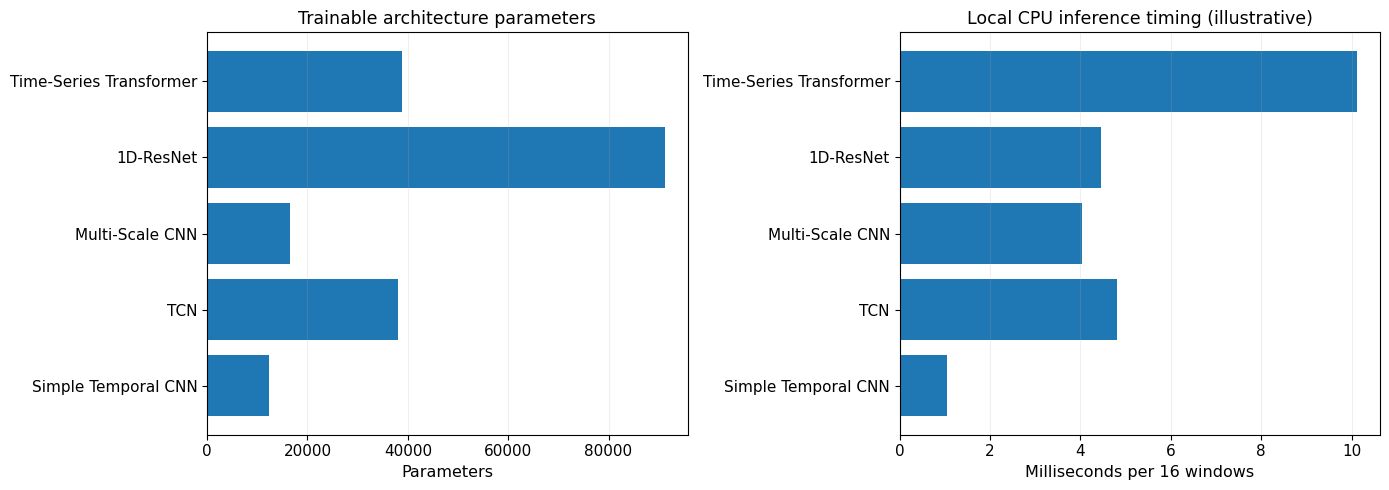

In [7]:
# ========= 06. Inspect Architecture Size and CPU Forward-Pass Timing =========

# ------------------- 1. Configure Comparative Model Timing -------------------
reference={"Simple Temporal CNN":TemporalCNN(6,8)}
models={name:build_temporal_model(name,6,8) for name in ARCHITECTURES}
models={**reference,**models}
timing_input=torch.randn(16,6,100)
rows=[]

# --------------------- 2. Measure CPU Forward-Pass Costs ---------------------
for name,model in models.items():
    model=model.cpu().eval()
    with torch.no_grad():
        for _ in range(2):
            logits=model(timing_input)
        starts=time.perf_counter()
        for _ in range(5):
            logits=model(timing_input)
        elapsed=(time.perf_counter()-starts)/5*1000  # Average over five CPU forward passes, in milliseconds.
    assert logits.shape==(16,8) and torch.isfinite(logits).all()
    rows.append({
        "architecture":name,
        "trainable_parameters":count_trainable_parameters(model),
        "cpu_ms_per_16_windows":elapsed,
        "logits_shape":str(tuple(logits.shape))
    })
capacity=pd.DataFrame(rows)
display(capacity.round(2))

# ----------------------- 3. Summarise Model Complexity -----------------------
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].barh(capacity["architecture"],capacity["trainable_parameters"])
axes[0].set(title="Trainable architecture parameters",xlabel="Parameters")
axes[1].barh(capacity["architecture"],capacity["cpu_ms_per_16_windows"])
axes[1].set(title="Local CPU inference timing (illustrative)",xlabel="Milliseconds per 16 windows")
for ax in axes:
    ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_temporal_architecture_complexity_timing.png")
plt.show()


**07. Prepare Participant-Disjoint HARTH Source Windows**

Use real-source windows from Development participants S006, S008, S012 and S013. Source-aligned windows are selected separately for three Train participants and one Validation participant, with a per-person cap of 32. Actual numbers and class support are displayed below; the small sample is an engineering check rather than a population performance estimate. Its size and class coverage do not support reliable model-performance comparisons.

In [8]:
# =========== 07. Prepare Participant-Disjoint HARTH Source Windows ===========

# -------------------- 1. Select Development Participants ---------------------
SMOKE_PEOPLE=["S006","S008","S012","S013"]
assert not(set(SMOKE_PEOPLE)&RESERVED_TEST)

# ------------------ 2. Prepare Participant-Disjoint Windows ------------------
X,y,metadata,overview=prepare_harth_window_cohort(
    subjects=SMOKE_PEOPLE,data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=32,
    window_size=100,step_size=50,sampling_rate=50
)

display(overview[["subject_id","eligible_windows","sampled_windows"]])
training_people={"S006","S008","S012"}
validation_people={"S013"}

# ------------------- 3. Check Signal Alignment and Scaling -------------------
train_idx=np.flatnonzero(metadata["subject_id"].isin(training_people).to_numpy())
val_idx=np.flatnonzero(metadata["subject_id"].isin(validation_people).to_numpy())

assert not(training_people&validation_people)
assert len(X)==len(metadata)==len(y) and len(X)>0
assert X.shape[1:]==(6,100) and len(train_idx)>=16 and len(val_idx)>0
assert set(np.unique(y)).issubset(CLASSES)
X_train,X_validation,train_statistics=standardise_imu_train_only(  # Fit normalisation statistics on Train participants only.
    X[train_idx],X[val_idx]
)

print("Real source Train:",X_train.shape,"| Validation:",X_validation.shape)
print("Actual classes observed in Train:",sorted(np.unique(y[train_idx]).tolist()))
print("All eight classes required in tiny smoke test: NO")


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S012.csv
HARTH subject S012: 382,414 rows, 6 sensors
Input signal: 382,414 samples, 6 channels
Candidate windows: 7,647
Retained windows: 7,309 | Shape: (7309, 6, 100)
Rejected candidates: 338
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S013.csv
HARTH subject S013: 369,077 rows, 6 sensors
Input signal: 369,077 samples, 6 channels
Candid

,subject_id,eligible_windows,sampled_windows
0,S006,6708,32
1,S008,7392,32
2,S012,7309,32
3,S013,6402,32


Real source Train: (96, 6, 100) | Validation: (32, 6, 100)
Actual classes observed in Train: [1, 3, 5, 6, 7, 8]
All eight classes required in tiny smoke test: NO


**08. Run One-Update Architecture Smoke Tests**

For each architecture, check finite Cross-Entropy loss, gradient propagation, trainable-parameter updates and output shapes using a single optimiser step. This verifies that the implementation runs on source data; it does not demonstrate training convergence, rare-class recall or predictive superiority.

In [9]:
# ================ 08. Run One-Update Architecture Smoke Tests ================

# -------------------- 1. Prepare Label and Tensor Inputs ---------------------
mapping={code:i for i,code in enumerate(CLASSES)}
batch_x=torch.from_numpy(X_train[:16])
batch_y=torch.tensor([mapping[int(label)] for label in y[train_idx[:16]]],dtype=torch.long)
val_tensor=torch.from_numpy(X_validation)

# ------------------- 2. Run One-Step Training Smoke Tests --------------------
training_rows=[]
for name in ARCHITECTURES:
    torch.manual_seed(SEED)
    network=build_temporal_model(name,6,8).cpu()
    optimizer=torch.optim.Adam(network.parameters(),lr=1e-3)
    before=[weight.detach().clone() for weight in network.parameters()]
    network.train()
    optimizer.zero_grad(set_to_none=True)
    loss=nn.CrossEntropyLoss()(network(batch_x),batch_y)
    assert torch.isfinite(loss).item()
    loss.backward()
    assert all(
        parameter.grad is not None and torch.isfinite(parameter.grad).all().item()
        for parameter in network.parameters() if parameter.requires_grad
    )
    optimizer.step()
    changed=any(not torch.equal(old,current.detach())
                for old,current in zip(before,network.parameters()))

# Infer on held-out participants without fitting on Validation.
    network.eval()
    with torch.no_grad():
        validation_logits=network(val_tensor)
    assert changed and validation_logits.shape==(len(val_idx),8)
    training_rows.append({
        "architecture":name,"initial_batch_loss":float(loss.item()),
        "optimizer_updates":1,"parameters_changed":changed,
        "held_out_output_shape":str(tuple(validation_logits.shape)),
        "finite_validation_logits":bool(torch.isfinite(validation_logits).all().item())
    })

# ----------------------- 3. Check Logits and Gradients -----------------------
smoke=pd.DataFrame(training_rows)

display(smoke.round(4))
print("Smoke training is not a predictive-performance benchmark.")


,architecture,initial_batch_loss,optimizer_updates,parameters_changed,held_out_output_shape,finite_validation_logits
0,TCN,2.2892,1,True,"(32, 8)",True
1,Multi-Scale CNN,1.8222,1,True,"(32, 8)",True
2,1D-ResNet,2.1541,1,True,"(32, 8)",True
3,Time-Series Transformer,2.4519,1,True,"(32, 8)",True


Smoke training is not a predictive-performance benchmark.


**09. Document Architectural Differences and Benchmark Controls**

TCN uses dilated temporal context; Multi-Scale CNN combines kernel widths; 1D-ResNet uses residual stages; and Transformer combines global token interactions with positional information. These are distinct modelling hypotheses. the matched Development benchmark below evaluates the architectures using matched source rows, participant-held-out folds and consistent metric definitions.

In [10]:
# ======= 09. Document Architectural Differences and Benchmark Controls =======

# ------------------- 1. Summarise Architecture Hypotheses --------------------
design_map=pd.DataFrame([
    {"architecture":"TCN","hypothesis":"Dilated temporal context helps distinguish related movement sequences","principal_risk":"Noncausal window context and receptive-field assumptions"},
    {"architecture":"Multi-Scale CNN","hypothesis":"Parallel kernels capture multiple movement timescales","principal_risk":"More filters, extra optimisation and potentially noisy small activities"},
    {"architecture":"1D-ResNet","hypothesis":"Residual depth learns expressive sequence features","principal_risk":"Overfitting and stride-related information loss"},
    {"architecture":"Time-Series Transformer","hypothesis":"Bidirectional self-attention captures longer-range within-window patterns","principal_risk":"Computational cost and data hunger"},
])

display(design_map)

# ---------------- 2. Document Matched Benchmark Requirements -----------------
controls=pd.DataFrame([
    {"constraint":"Same windows and subject folds","status":"Required"},
    {"constraint":"Train-only sensor standardisation and class weights","status":"Required"},
    {"constraint":"Fixed eight-code class denominator and Macro F1","status":"Required"},
    {"constraint":"Per-class Shuffling/stairs performance and support","status":"Required"},
    {"constraint":"Compute/parameters/latency reporting","status":"Required"},
    {"constraint":"Original Test subjects S023/S032 excluded","status":"Required"},
    {"constraint":"Reproducibility over more than one seed","status":"Separate robustness analysis"},
])

display(controls)


,architecture,hypothesis,principal_risk
0,TCN,Dilated temporal context helps distinguish rel...,Noncausal window context and receptive-field a...
1,Multi-Scale CNN,Parallel kernels capture multiple movement tim...,"More filters, extra optimisation and potential..."
2,1D-ResNet,Residual depth learns expressive sequence feat...,Overfitting and stride-related information loss
3,Time-Series Transformer,Bidirectional self-attention captures longer-r...,Computational cost and data hunger


,constraint,status
0,Same windows and subject folds,Required
1,Train-only sensor standardisation and class we...,Required
2,Fixed eight-code class denominator and Macro F1,Required
3,Per-class Shuffling/stairs performance and sup...,Required
4,Compute/parameters/latency reporting,Required
5,Original Test subjects S023/S032 excluded,Required
6,Reproducibility over more than one seed,Separate robustness analysis


**10. Review Engineering Checks and Export Evidence**

Confirm the intended six-channel temporal input contract, four implemented advanced architectures, finite gradients and updated parameters, the selected source participants, and Train-only standardisation. Export the current engineering tables with `10_` filenames. These checks do not assess independent predictive accuracy or establish model superiority. The following sections perform the separately bounded seven-model Development comparison.

In [11]:
# ============= 10. Review Engineering Checks and Export Evidence =============

# ---------------- 1. Verify Architecture and Input Integrity -----------------
assert len(ARCHITECTURES)==4
assert set(ARCHITECTURES)==set(smoke["architecture"])
assert set(capacity["architecture"])==set(ARCHITECTURES)|{"Simple Temporal CNN"}
assert all(capacity["trainable_parameters"]>0)
assert capacity["logits_shape"].eq("(16, 8)").all()
assert X.ndim==3 and X.shape[1:]==(len(SENSOR_COLUMNS),100)
assert metadata["subject_id"].nunique()==4
assert not(set(metadata["subject_id"])&RESERVED_TEST)
assert not(training_people&validation_people)
assert np.isfinite(X_train).all() and np.isfinite(X_validation).all()

# -------------------- 2. Check Training Steps and Logits ---------------------
assert smoke["optimizer_updates"].eq(1).all()
assert smoke["parameters_changed"].all()
assert smoke["finite_validation_logits"].all()
assert smoke["held_out_output_shape"].eq(str((len(val_idx),len(CLASSES)))).all()

# -------------------- 3. Quality Gate and Evidence Limits --------------------
print("NOTEBOOK 10: FOUR ADVANCED TEMPORAL ARCHITECTURES")
print("="*66)
print("Temporal Convolutional Network: IMPLEMENTED AND SMOKE-TESTED")
print("Multi-Scale CNN: IMPLEMENTED AND SMOKE-TESTED")
print("1D-ResNet: IMPLEMENTED AND SMOKE-TESTED")
print("Time-Series Transformer: IMPLEMENTED AND SMOKE-TESTED")
print("Common (batch, channels, time) contract: PASSED")
print("Real-data Train/Validation participant separation: PASSED")
print("Finite gradients and one-step updates: PASSED")
print("Original protected Test used: NO")
print("*"*66)
print("Engineering evidence: inspected and saved")
print("Engineering checks alone do not establish model performance.")
print("Independent predictive generalisation established: NO")
print("Next in this notebook: matched seven-model Development benchmark.")

# ------------------------ 4. Save Architecture Audit Results ----------------
capacity.to_csv(output_dir / "10_architecture_capacity_cpu_timing.csv", index=False)
overview.to_csv(output_dir / "10_smoke_source_cohort_summary.csv", index=False)
smoke.to_csv(output_dir / "10_architecture_single_update_smoke_tests.csv", index=False)
design_map.to_csv(output_dir / "10_architecture_research_hypotheses.csv", index=False)
controls.to_csv(output_dir / "10_matched_benchmark_design_controls.csv", index=False)
pd.DataFrame([
    {"partition": role, "subject_id": person}
    for role, people in [
        ("train", sorted(training_people)),
        ("validation", sorted(validation_people)),
    ]
    for person in people
]).to_csv(output_dir / "10_smoke_train_validation_people.csv", index=False)
print("Saved architecture engineering results in:", output_dir)



NOTEBOOK 10: FOUR ADVANCED TEMPORAL ARCHITECTURES
Temporal Convolutional Network: IMPLEMENTED AND SMOKE-TESTED
Multi-Scale CNN: IMPLEMENTED AND SMOKE-TESTED
1D-ResNet: IMPLEMENTED AND SMOKE-TESTED
Time-Series Transformer: IMPLEMENTED AND SMOKE-TESTED
Common (batch, channels, time) contract: PASSED
Real-data Train/Validation participant separation: PASSED
Finite gradients and one-step updates: PASSED
Original protected Test used: NO
******************************************************************
Engineering evidence: inspected and saved
Engineering checks alone do not establish model performance.
Independent predictive generalisation established: NO
Next in this notebook: matched seven-model Development benchmark.
Saved architecture engineering results in: /content/human-movement-intelligence/wearable_activity_recognition/output


**11. Fixed Grouped Benchmark Protocol and Compute Boundary**

The engineering probes above are intentionally small and do not share their four-person split with this benchmark. The benchmark reconstructs a distinct label-blind 500-window-per-participant cohort from **29 Development participants**, then applies three common participant-disjoint GroupKFold folds to all seven classifiers.

The approved protocol uses 400 Adam updates per neural fold, batch size 128, learning rate `0.001`, seed 42 and the recorded loss/scaling rules. CUDA is required for this benchmark; no automatic training begins during the earlier engineering sections. The established Git-ignored cache path is preserved to allow validated model–fold records to be reused after their complete source/configuration fingerprints and prediction identities have been checked. A missing or incompatible cache entry triggers its corresponding training job when Section 15 is explicitly executed.

In [12]:
# ========= 11. Fixed Grouped Benchmark Protocol and Compute Boundary =========

# ---------------- 1. Configure the Matched Development Cohort ----------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
FOLDS = 3
MAX_WINDOWS_PER_SUBJECT = 500
MAX_STEPS = 400
BATCH_SIZE = 128
CACHE_DIR = root / "data/processed/harth_stage23_matched_benchmark"

if not DEVELOPMENT_SUBJECTS or set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST:
    raise ValueError("Invalid participant split for Development evaluation.")
if len(MODEL_NAMES) != 7:
    raise ValueError("The approved benchmark requires seven model configurations.")

# --------------- 2. Enforce the Approved Compute Requirements ----------------
if DEVICE != "cuda":
    raise RuntimeError(
        "This fixed 400-update benchmark requires a CUDA GPU. "
        "Use a Colab GPU runtime for Sections 11–22."
    )
torch.set_float32_matmul_precision("highest")
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# --------------- 3. Describe the Reusable Scientific Protocol ----------------
print("Development participants:", len(DEVELOPMENT_SUBJECTS))
print("Selected model families:", ", ".join(MODEL_NAMES))
print("Benchmark protocol:", PROTOCOL_VERSION)
print("GroupKFold partitions:", FOLDS)
print("Neural updates / batch size:", MAX_STEPS, "/", BATCH_SIZE)
print("Validated local cache directory:", CACHE_DIR)
print("Held-out assessment participants excluded:", sorted(RESERVED_TEST))


Development participants: 29
Selected model families: Random Forest, Standard CNN, Weighted CNN, TCN, Multi-Scale CNN, 1D-ResNet, Time-Series Transformer
Benchmark protocol: harth-stage23-matched-500cap-group3-fixed400-v1
GroupKFold partitions: 3
Neural updates / batch size: 400 / 128
Validated local cache directory: /content/human-movement-intelligence/data/processed/harth_stage23_matched_benchmark
Held-out assessment participants excluded: ['S023', 'S032']


**12. Reconstruct Bounded Development Windows**

Reconstruct the bounded Development cohort from the 29 recorded participant IDs (historically 14,201 windows) using 100-sample windows, 50-sample strides, label purity and timestamp-continuity checks. The 500-window-per-participant cap samples eligible positions without activity-label selection. Overlapping windows remain correlated despite participant-level independence between folds.

In [13]:
# ================ 12. Reconstruct Bounded Development Windows ================

# --------------- 1. Prepare Matched Development Source Windows ---------------
X,y,metadata,overview=prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,
    window_size=100,step_size=50,sampling_rate=50,
)
assert X.ndim==3 and X.shape[1:]==(len(SENSOR_COLUMNS),100) and len(X)>0
assert len(y)==len(metadata) and metadata["subject_id"].nunique()==29
assert not(set(metadata["subject_id"])&RESERVED_TEST)

# ---------------- 2. Summarise Activity and Source Provenance ----------------
counts=pd.crosstab(
    metadata["subject_id"],metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS,columns=CLASSES,fill_value=0)

coverage=pd.DataFrame({
    "activity":[ACTIVITY_NAMES[c] for c in CLASSES],
    "windows":counts.sum(axis=0).to_numpy(),
    "supporting_subjects":(counts>0).sum(axis=0).to_numpy(),
})
display(overview[["subject_id","eligible_windows","sampled_windows"]])
display(coverage)

print("True raw IMU tensor:",X.shape)
print("Window class codes:",sorted(np.unique(y).tolist()))

# ------------------ 3. Export Development Cohort Support --------------------
overview.to_csv(output_dir / "10_development_cohort_summary.csv", index=False)
coverage.to_csv(output_dir / "10_development_activity_support.csv", index=False)


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


,activity,windows,supporting_subjects
0,Walking,3591,29
1,Running,1028,19
2,Shuffling,219,26
3,Stairs ascending,192,24
4,Stairs descending,182,25
5,Standing,2227,29
6,Sitting,5599,28
7,Lying,1163,23


True raw IMU tensor: (14201, 6, 100)
Window class codes: [1, 2, 3, 4, 5, 6, 7, 8]


**13. Validate Participant-Grouped Fold Membership**

Assign complete participants to three common held-out folds. Every model evaluates the same source rows and labels, with each Development row held out once. A SHA256 fingerprint links saved predictions to the source-window cohort, class definitions and protocol.

In [ ]:
# ============= 13. Validate Participant-Grouped Fold Membership ==============

# ---------------- 1. Fingerprint Development Source and Folds ----------------
plan=make_benchmark_plan(
    windows=X,labels=y,subject_ids=metadata["subject_id"].to_numpy(),
    classes=CLASSES,n_splits=FOLDS,forbidden_subjects=RESERVED_TEST
)

fold_design=[]

# -------------------- 2. Build Participant-Disjoint Folds --------------------
for fold,tr,va in plan["folds"]:
    tr_groups=set(plan["groups"][tr])
    va_groups=set(plan["groups"][va])
    assert not(tr_groups&va_groups)
    fold_design.append({
        "fold":fold,"train_subjects":len(tr_groups),
        "validation_subjects":len(va_groups),
        "train_windows":len(tr),"validation_windows":len(va),
        "train_classes":len(np.unique(y[tr])),
        "validation_classes":len(np.unique(y[va])),
        "validation_subject_ids":", ".join(sorted(va_groups)),
    })

display(pd.DataFrame(fold_design))
print("Source SHA256:",plan["fingerprint"])
print("Complete model-by-fold jobs required:",len(MODEL_NAMES)*FOLDS)

# ---------------------- 3. Export Fold Membership ----------------------------
pd.DataFrame(fold_design).to_csv(output_dir / "10_matched_fold_design.csv", index=False)


,fold,train_subjects,validation_subjects,train_windows,validation_windows,train_classes,validation_classes,validation_subject_ids
0,1,19,10,9201,5000,8,8,"S006, S012, S015, S018, S021, S025, S028, S031..."
1,2,19,10,9500,4701,8,8,"S009, S010, S014, S017, S020, S024, S027, S030..."
2,3,20,9,9701,4500,8,8,"S008, S013, S016, S019, S022, S026, S029, S033..."


Source SHA256: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Complete model-by-fold jobs required: 21


**14. Specify Seven-Model Training Configurations**

Train six neural architectures for 400 Adam updates per fold, using batch size 128 and learning rate `0.001`. Standard CNN uses unweighted Cross-Entropy; the other five neural configurations use inverse-square-root class weights from fold Train labels. Neural channel scaling also uses Train only.

Random Forest uses 30 statistical features, 120 trees, minimum leaf size three and balanced-subsample weighting. These settings support a common end-to-end evaluation, not an architecture-only causal comparison.

In [ ]:
# ============== 14. Specify Seven-Model Training Configurations ==============

# ----------------- 1. Specify Matched Model Representations ------------------
protocol=pd.DataFrame([
    {"model":name,"representation":
      "30 deterministic signal features" if name=="Random Forest" else "6 x 100 raw IMU",
     "training":
      "120-tree balanced-subset RF" if name=="Random Forest"
      else "400 Adam updates; inverse-sqrt weighted CE"
      if name!="Standard CNN" else "400 Adam updates; unweighted CE"}
    for name in MODEL_NAMES
])

display(protocol)

# --------------------- 2. Extract Random Forest Features ---------------------
features=extract_signal_features(X,channel_names=SENSOR_COLUMNS)
assert features.shape==(len(X),30)
assert np.isfinite(features.to_numpy()).all()

rf_features=features.to_numpy()

print("RF feature matrix:",rf_features.shape)
print("All CNN/Transformer input rows matched with RF source rows: YES")

# ---------------------- 3. Export Model Protocols ----------------------------
protocol.to_csv(output_dir / "10_model_protocols.csv", index=False)


,model,representation,training
0,Random Forest,30 deterministic signal features,120-tree balanced-subset RF
1,Standard CNN,6 x 100 raw IMU,400 Adam updates; unweighted CE
2,Weighted CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
3,TCN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
4,Multi-Scale CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
5,1D-ResNet,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
6,Time-Series Transformer,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
RF feature matrix: (14201, 30)
All CNN/Transformer input rows matched with RF source rows: YES


**15. Run or Restore the 21 Matched Model-Fold Jobs**

This stage runs or restores seven classifiers across three participant-disjoint folds: 18 neural fits and three Random Forest fits. Successful jobs write source-row IDs, labels, predictions, configuration fingerprints, metrics and timings to a Git-ignored local cache. On rerun, compatible completed jobs can be verified and reused. A complete benchmark requires all 21 jobs to pass source-alignment checks.

In [16]:
# ============= 15. Run or Restore the 21 Matched Model-Fold Jobs =============

# ---------------------- 1. Run Matched Model-Fold Jobs -----------------------
jobs=[]

for fold,tr,va in plan["folds"]:
    print("\n"+"="*70)
    print(f"FOLD {fold}/{FOLDS}: TRAIN {len(tr):,} | VALIDATION {len(va):,}")
    print("="*70)
    for model_name in MODEL_NAMES:
        result=run_benchmark_job(
            plan=plan,fold=fold,model_name=model_name,
            cache_dir=CACHE_DIR,feature_matrix=rf_features,
            max_steps=MAX_STEPS,batch_size=BATCH_SIZE,learning_rate=1e-3,
            seed=SEED,device=DEVICE,
        )
        jobs.append(result)

# ------------------------- 2. Verify Job Completion --------------------------
assert len(jobs)==7*FOLDS
print("\n"+"="*70)
print("ALL 21 MATCHED MODEL–FOLD RECORDS AVAILABLE")
print("Local cache:",CACHE_DIR)
print("Predictions and metrics were generated from actual models: YES")
print("="*70)



FOLD 1/3: TRAIN 9,201 | VALIDATION 5,000
RUNNING Fold 1 | Random Forest | Train=9,201 Validation=5,000
FINISHED Fold 1 | Random Forest | Macro F1=0.7969 | Train=3.9 s
RUNNING Fold 1 | Standard CNN | Train=9,201 Validation=5,000
  Standard CNN: 100/400 updates | Train loss 0.4504
  Standard CNN: 200/400 updates | Train loss 0.2253
  Standard CNN: 300/400 updates | Train loss 0.1815
  Standard CNN: 400/400 updates | Train loss 0.2678
FINISHED Fold 1 | Standard CNN | Macro F1=0.7204 | Train=1.9 s
RUNNING Fold 1 | Weighted CNN | Train=9,201 Validation=5,000
  Weighted CNN: 100/400 updates | Train loss 0.7943
  Weighted CNN: 200/400 updates | Train loss 0.3456
  Weighted CNN: 300/400 updates | Train loss 0.2478
  Weighted CNN: 400/400 updates | Train loss 0.3312
FINISHED Fold 1 | Weighted CNN | Macro F1=0.7418 | Train=1.9 s
RUNNING Fold 1 | TCN | Train=9,201 Validation=5,000
  TCN: 100/400 updates | Train loss 0.5742
  TCN: 200/400 updates | Train loss 0.2971
  TCN: 300/400 updates | Train

**16. Reconstruct Out-of-Fold Predictions and Metrics**

Reconstruct accuracy, balanced accuracy, fixed eight-class Macro F1, class-specific precision/recall/F1, confusion matrices and one score per held-out participant. Reject incomplete or duplicated prediction records and mismatched source identities. Aggregate accuracy alone does not establish minority-class recognition.

In [ ]:
# ============ 16. Reconstruct Out-of-Fold Predictions and Metrics ============

# Evidence locator retained for downstream readers: 06. Complete Benchmark Results

# ------------------ 1. Reconstruct Out-of-Fold Predictions -------------------
fold_results,subject_results,class_results,predictions,confusion=(
    summarise_benchmark_results(plan,jobs)
)
display(fold_results[[
    "model","fold","train_subjects","validation_subjects",
    "train_windows","validation_windows","macro_f1",
    "balanced_accuracy","accuracy","train_seconds",
    "validation_inference_seconds","trainable_parameters",
]].round(4))

# ---------------------- 2. Summarise Benchmark Metrics -----------------------
summary=fold_results.groupby("model",as_index=False).agg(
    macro_f1_mean=("macro_f1","mean"),
    macro_f1_sd=("macro_f1","std"),
    balanced_accuracy_mean=("balanced_accuracy","mean"),
    accuracy_mean=("accuracy","mean"),
    total_train_seconds=("train_seconds","sum"),
    total_inference_seconds=("validation_inference_seconds","sum"),
    parameters=("trainable_parameters","max"),
)

display(summary.sort_values("macro_f1_mean",ascending=False).round(4))
print("All source rows evaluated once per model:",len(X))
print("Independent Validation participant coverage:",len(DEVELOPMENT_SUBJECTS))

# ------------------- 3. Export Complete Benchmark Evidence -------------------
fold_results.to_csv(output_dir / "10_matched_cv_fold_metrics.csv", index=False)
subject_results.to_csv(output_dir / "10_matched_cv_subject_metrics.csv", index=False)
predictions.to_csv(output_dir / "10_matched_cv_oof_predictions.csv", index=False)
summary.to_csv(output_dir / "10_matched_cv_model_summary.csv", index=False)


,model,fold,train_subjects,validation_subjects,train_windows,validation_windows,macro_f1,balanced_accuracy,accuracy,train_seconds,validation_inference_seconds,trainable_parameters
0,1D-ResNet,1,19,10,9201,5000,0.7897,0.8712,0.9292,2.6577,0.0336,91176
1,1D-ResNet,2,19,10,9500,4701,0.8360,0.8780,0.9528,2.5126,0.0316,91176
2,1D-ResNet,3,20,9,9701,4500,0.8751,0.8577,0.9591,3.1723,0.0429,91176
3,Multi-Scale CNN,1,19,10,9201,5000,0.7526,0.8690,0.9226,2.6845,0.0429,16488
4,Multi-Scale CNN,2,19,10,9500,4701,0.7854,0.8055,0.9300,3.4222,0.0374,16488
5,Multi-Scale CNN,3,20,9,9701,4500,0.8478,0.8431,0.9567,2.5889,0.0343,16488
6,Random Forest,1,19,10,9201,5000,0.7969,0.8368,0.9418,3.9228,0.0558,0
7,Random Forest,2,19,10,9500,4701,0.7669,0.7608,0.9566,4.1174,0.0548,0
8,Random Forest,3,20,9,9701,4500,0.8645,0.8213,0.9613,5.7464,0.0557,0
9,Standard CNN,1,19,10,9201,5000,0.7204,0.6975,0.9390,1.9050,0.0260,12392


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8336,0.0427,0.8689,0.9470,8.3426,0.1081,91176
4,TCN,0.8138,0.0658,0.8575,0.9365,8.9361,0.1223,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,13.7867,0.1663,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,13.1165,0.3009,38744
1,Multi-Scale CNN,0.7953,0.0483,0.8392,0.9364,8.6957,0.1145,16488
6,Weighted CNN,0.7721,0.0269,0.8021,0.9411,4.7973,0.0497,12392
3,Standard CNN,0.6660,0.0628,0.6576,0.9379,4.9593,0.0587,12392


All source rows evaluated once per model: 14201
Independent Validation participant coverage: 29


**17. Compare Matched Development Fold Results**

Compute model rankings from the current held-out model–fold results. Fold means and variability are descriptive; three folds do not establish statistical superiority or independent generalisation.

fold,1,2,3
model,,,
Random Forest,0.7969,0.7669,0.8645
Standard CNN,0.7204,0.6804,0.5973
Weighted CNN,0.7418,0.7815,0.7931
TCN,0.7634,0.7898,0.8883
Multi-Scale CNN,0.7526,0.7854,0.8478
1D-ResNet,0.7897,0.8360,0.8751
Time-Series Transformer,0.7413,0.7991,0.8616


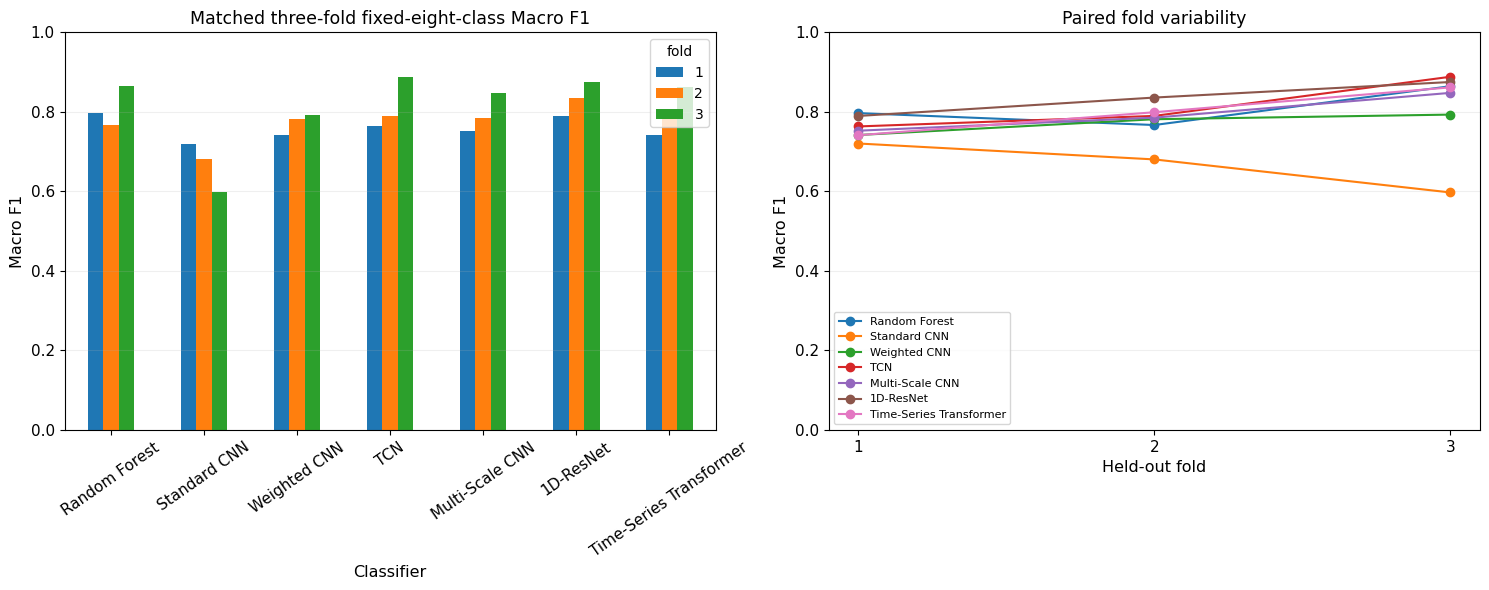

In [18]:
# =============== 17. Compare Matched Development Fold Results ================

# ---------------------- 1. Compare Fold-Level Macro F1 -----------------------
wide=fold_results.pivot(index="model",columns="fold",values="macro_f1"
).reindex(MODEL_NAMES)

display(wide.round(4))
wide.rename_axis("model").reset_index().to_csv(
    output_dir / "10_matched_cv_fold_comparison.csv", index=False
)

# ------------------ 2. Visualise Matched Model Performance -------------------
fig,axes=plt.subplots(1,2,figsize=(15,6))

wide.plot(kind="bar",ax=axes[0],rot=35,ylim=(0,1))
axes[0].set(title="Matched three-fold fixed-eight-class Macro F1",
            xlabel="Classifier",ylabel="Macro F1")

for model in MODEL_NAMES:
    rows=fold_results[fold_results["model"]==model].sort_values("fold")
    axes[1].plot(rows["fold"],rows["macro_f1"],marker="o",label=model)
axes[1].set(title="Paired fold variability",xlabel="Held-out fold",
            ylabel="Macro F1",ylim=(0,1),xticks=[1,2,3])
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_fold_macro_f1.png")
plt.show()


**18. Analyse Minority Activities and Confusion Matrices**

Report precision, recall, F1 and support for all eight source activities, including Shuffling and both stair classes. Shuffling has only 219 source windows in the bounded cohort. Use consistent class ordering in confusion matrices and interpret pooled window metrics as correlated observations.

,model,class_code,activity,support,precision,recall,f1
0,Random Forest,1,Walking,3591,0.9272,0.9510,0.9390
1,Random Forest,2,Running,1028,0.9836,0.9903,0.9869
2,Random Forest,3,Shuffling,219,0.4756,0.5342,0.5032
3,Random Forest,4,Stairs ascending,192,0.7310,0.5521,0.6291
4,Random Forest,5,Stairs descending,182,0.7031,0.4945,0.5806
5,Random Forest,6,Standing,2227,0.9382,0.9618,0.9499
6,Random Forest,7,Sitting,5599,0.9969,0.9791,0.9879
7,Random Forest,8,Lying,1163,0.9831,0.9991,0.9910
8,Standard CNN,1,Walking,3591,0.8975,0.9563,0.9260
9,Standard CNN,2,Running,1028,0.9873,0.9844,0.9859


,model,activity,support,recall,f1
2,Random Forest,Shuffling,219,0.5342,0.5032
3,Random Forest,Stairs ascending,192,0.5521,0.6291
4,Random Forest,Stairs descending,182,0.4945,0.5806
10,Standard CNN,Shuffling,219,0.0000,0.0000
11,Standard CNN,Stairs ascending,192,0.1198,0.2009
12,Standard CNN,Stairs descending,182,0.2033,0.3304
18,Weighted CNN,Shuffling,219,0.1050,0.1394
19,Weighted CNN,Stairs ascending,192,0.8073,0.5688
20,Weighted CNN,Stairs descending,182,0.6374,0.6170
26,TCN,Shuffling,219,0.3973,0.3392


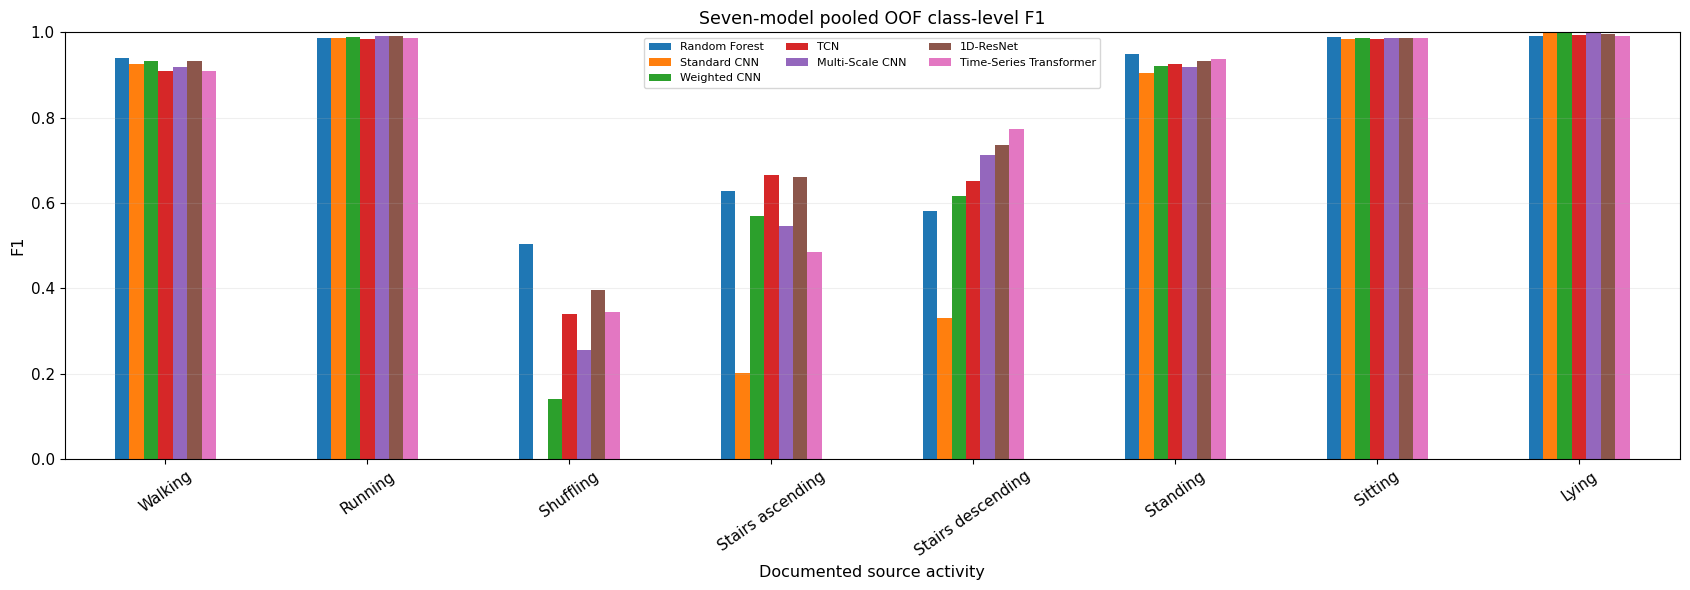

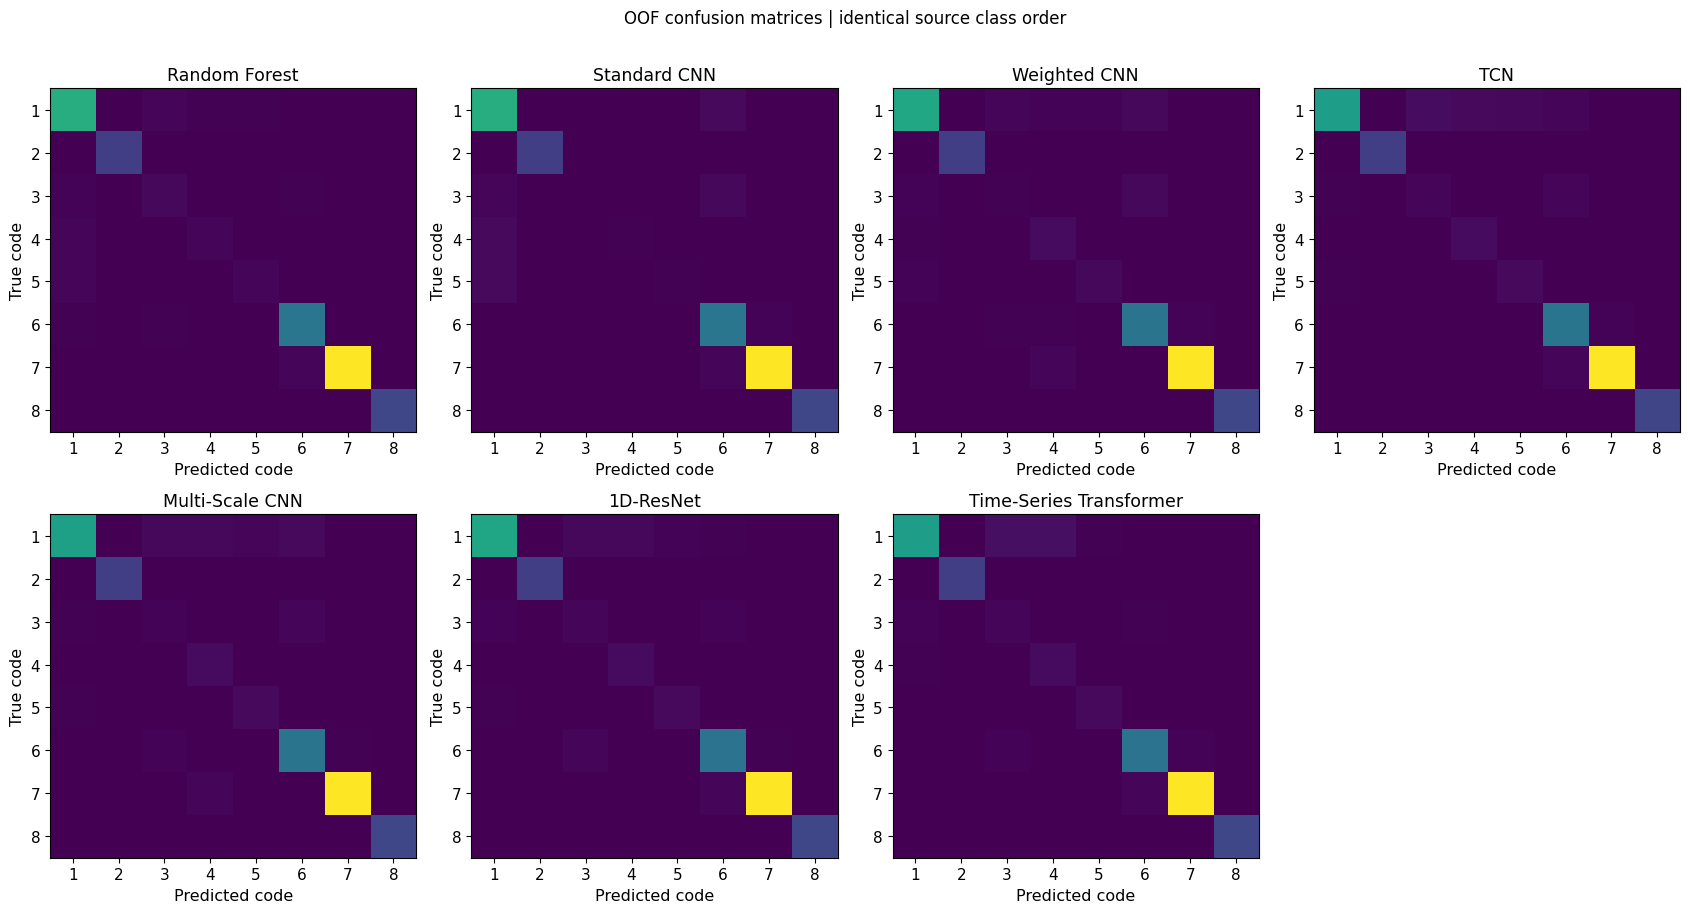

In [19]:
# ========== 18. Analyse Minority Activities and Confusion Matrices ===========

# Evidence locator retained for downstream readers: 08. Minority-Class Reporting

# -------------------- 1. Audit Minority-Class Predictions --------------------
class_results["activity"]=class_results["class_code"].map(ACTIVITY_NAMES)
class_results.to_csv(output_dir / "10_matched_cv_class_metrics.csv", index=False)

display(class_results[[
    "model","class_code","activity","support","precision","recall","f1"
]].round(4))
minority=class_results[class_results["class_code"].isin([3,4,5])]
minority.to_csv(output_dir / "10_matched_cv_minority_metrics.csv", index=False)

display(minority[["model","activity","support","recall","f1"]].round(4))

# ------------------- 2. Visualise Class F1 and Confusions --------------------
class_pivot=class_results.pivot(index="activity",columns="model",values="f1")
class_pivot=class_pivot.reindex([ACTIVITY_NAMES[c] for c in CLASSES])
class_pivot=class_pivot.reindex(columns=MODEL_NAMES)
class_pivot.rename_axis("activity").reset_index().to_csv(
    output_dir / "10_matched_cv_per_class_f1.csv", index=False
)

fig,ax=plt.subplots(figsize=(17,6))
class_pivot.plot(kind="bar",ax=ax,rot=35,ylim=(0,1))
ax.set(title="Seven-model pooled OOF class-level F1",
       xlabel="Documented source activity",ylabel="F1")
ax.legend(fontsize=8,ncol=3)
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_cv_per_class_f1.png")
plt.show()
fig,axes=plt.subplots(2,4,figsize=(17,9))

for ax,name in zip(axes.flat,MODEL_NAMES):
    matrix=confusion[name]
    ax.imshow(matrix,interpolation="nearest",aspect="auto")
    ax.set(title=name,xlabel="Predicted code",ylabel="True code")
    ax.set_xticks(range(8),CLASSES)
    ax.set_yticks(range(8),CLASSES)
for ax in list(axes.flat)[len(MODEL_NAMES):]:
    ax.axis("off")
fig.suptitle("OOF confusion matrices | identical source class order",y=1.01)
fig.tight_layout()
# ------------------- 3. Export Matched Confusion Matrices --------------------
for name, matrix in confusion.items():
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).rename_axis(
        "true_class"
    ).to_csv(output_dir / f"10_confusion_{safe_name}.csv")
save_figure(fig, output_dir / "10_matched_cv_confusion_matrices.png")
plt.show()


**19. Inspect Participant-Level Model Variation**

Summarise fixed eight-class Macro F1 for each held-out participant rather than treating overlapping windows as independent people. Distinguish fixed-task Macro F1 from metrics restricted to classes observed for one participant. This comparison is not an analysis of demographic fairness.

model,Random Forest,Standard CNN,Weighted CNN,TCN,Multi-Scale CNN,1D-ResNet,Time-Series Transformer
subject_id,,,,,,,
S006,0.6826,0.4580,0.6860,0.7905,0.7214,0.7608,0.7326
S008,0.4254,0.3397,0.3561,0.5138,0.4542,0.5541,0.5578
S009,0.3261,0.2319,0.3460,0.4180,0.4268,0.4100,0.4070
S010,0.4445,0.3540,0.6317,0.5352,0.5428,0.6324,0.5743
S012,0.8718,0.5842,0.7733,0.9325,0.9114,0.9173,0.6181
S013,0.6790,0.5508,0.7424,0.8082,0.8534,0.8677,0.7426
S014,0.8071,0.5918,0.7996,0.7984,0.7315,0.7690,0.8315
S015,0.7156,0.6527,0.7412,0.7410,0.7866,0.8136,0.6370
S016,0.7160,0.6119,0.6119,0.7953,0.7845,0.8592,0.7982


Participants per model: {'Random Forest': 29, 'Standard CNN': 29, 'Weighted CNN': 29, 'TCN': 29, 'Multi-Scale CNN': 29, '1D-ResNet': 29, 'Time-Series Transformer': 29}


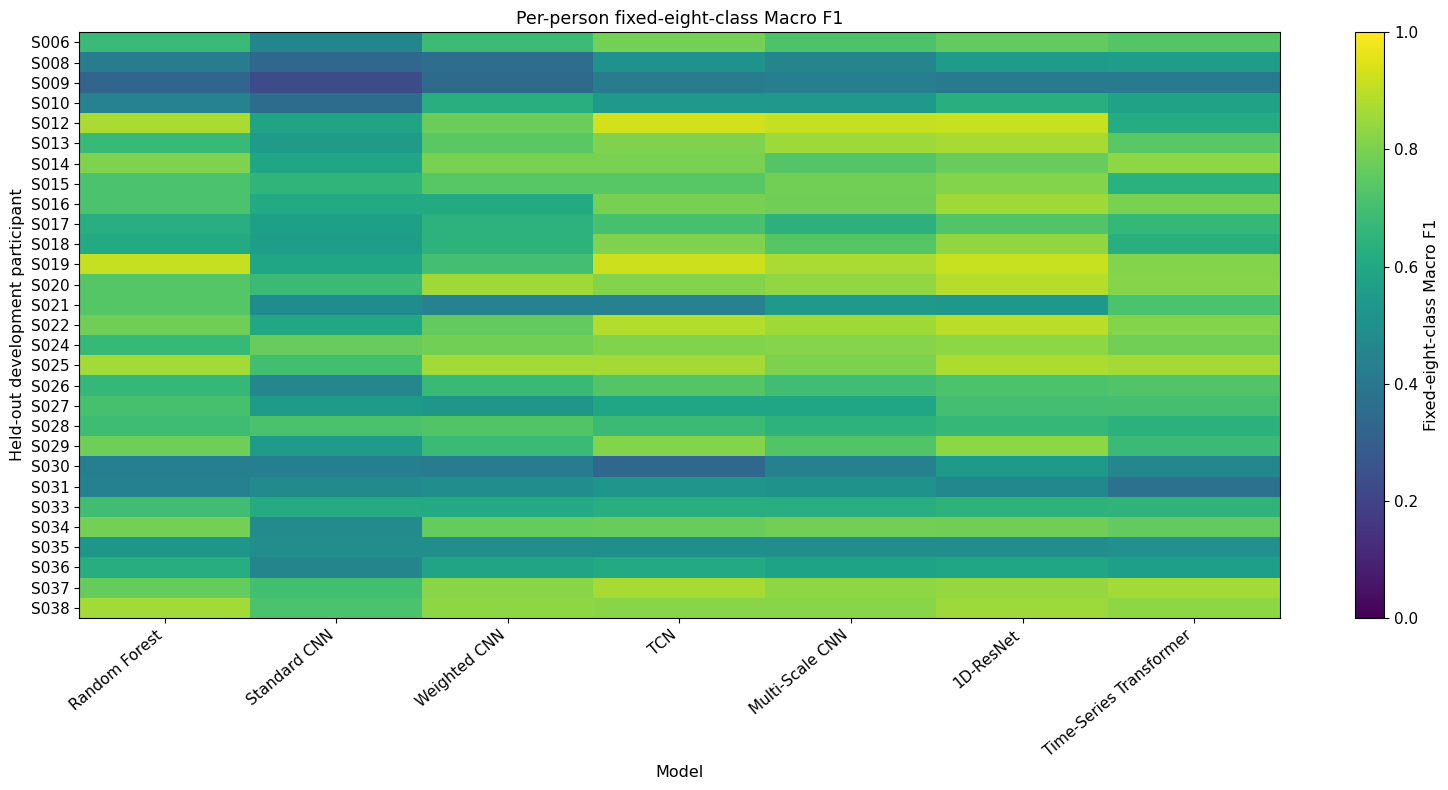

In [ ]:
# =============== 19. Inspect Participant-Level Model Variation ===============

# ------------------- 1. Summarise Participant-Level Scores -------------------
individual=subject_results.pivot(
    index="subject_id",columns="model",values="macro_f1_fixed_task"
).reindex(index=DEVELOPMENT_SUBJECTS,columns=MODEL_NAMES)

display(individual.round(4))
individual.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "10_matched_cv_participant_comparison.csv", index=False
)
assert individual.notna().all().all()
print("Participants per model:",individual.notna().sum().to_dict())

# ---------------------- 2. Visualise Subject Variation -----------------------
fig,ax=plt.subplots(figsize=(14,8))

im=ax.imshow(individual.to_numpy(),aspect="auto",vmin=0,vmax=1)
ax.set_xticks(range(len(MODEL_NAMES)),MODEL_NAMES,rotation=40,ha="right")
ax.set_yticks(range(len(DEVELOPMENT_SUBJECTS)),DEVELOPMENT_SUBJECTS)
ax.set(title="Per-person fixed-eight-class Macro F1",xlabel="Model",
       ylabel="Held-out development participant")

fig.colorbar(im,ax=ax,label="Fixed-eight-class Macro F1")
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_cv_participant_f1.png")
plt.show()


**20. Report Training Cost and Architecture Capacity**

Report neural parameter counts, Random Forest tree settings, model-fitting times and Validation inference cost with clear hardware context. Cached job outputs contain predictions and metrics, not reusable trained weights. Separate final Development fitting and model artefacts are outside this matched Development benchmark.

,model,total_train_s,mean_train_s_per_fold,total_validation_inference_s,trainable_parameters
0,1D-ResNet,8.343,2.781,0.108,91176
1,Multi-Scale CNN,8.696,2.899,0.115,16488
2,Random Forest,13.787,4.596,0.166,0
3,Standard CNN,4.959,1.653,0.059,12392
4,TCN,8.936,2.979,0.122,38056
5,Time-Series Transformer,13.116,4.372,0.301,38744
6,Weighted CNN,4.797,1.599,0.050,12392


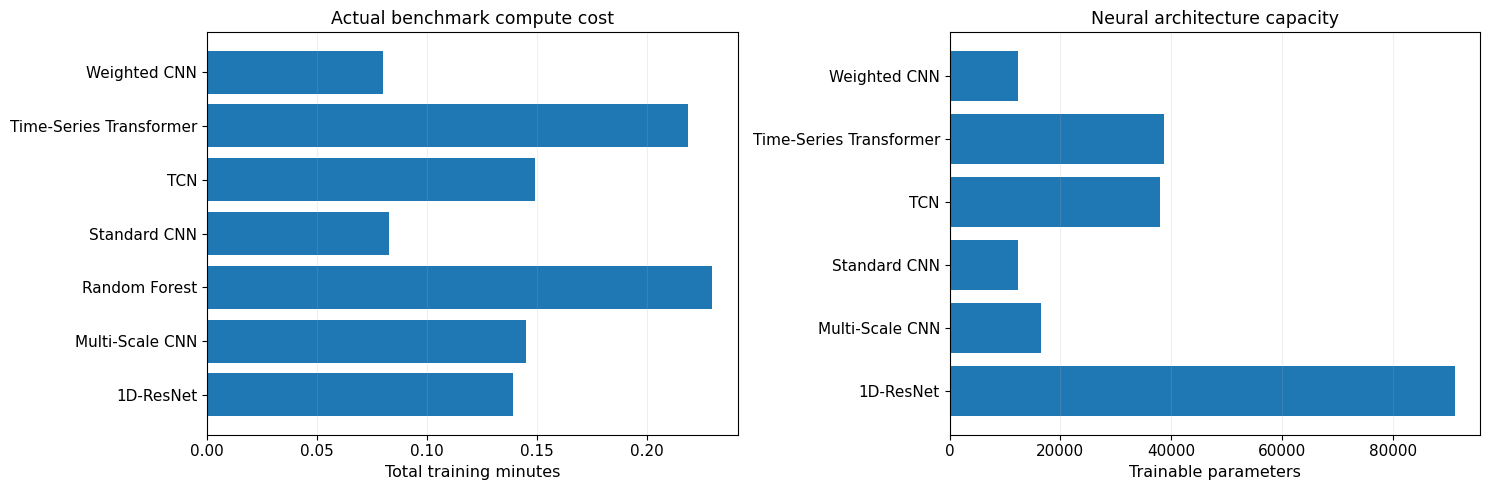

Stored source fingerprint: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Model scores reproduced from actual saved held-out predictions: YES


In [21]:
# ============ 20. Report Training Cost and Architecture Capacity =============

# ---------------------- 1. Review Model Training Costs -----------------------
costs=fold_results.groupby("model",as_index=False).agg(
    total_train_s=("train_seconds","sum"),
    mean_train_s_per_fold=("train_seconds","mean"),
    total_validation_inference_s=("validation_inference_seconds","sum"),
    trainable_parameters=("trainable_parameters","max"),
)

display(costs.round(3))
costs.to_csv(output_dir / "10_matched_cv_model_compute_costs.csv", index=False)
fig,axes=plt.subplots(1,2,figsize=(15,5))

axes[0].barh(costs["model"],costs["total_train_s"]/60)
axes[0].set(xlabel="Total training minutes",title="Actual benchmark compute cost")

neural=costs[costs["model"]!="Random Forest"]

axes[1].barh(neural["model"],neural["trainable_parameters"])
axes[1].set(xlabel="Trainable parameters",title="Neural architecture capacity")
for ax in axes: ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_cv_compute_costs.png")
plt.show()

# ---------------------- 2. Record Benchmark Provenance -----------------------
print("Stored source fingerprint:",plan["fingerprint"])
print("Model scores reproduced from actual saved held-out predictions: YES")


**21. Interpret the Matched Development Evidence**

These matched Development results support an architecture shortlist, but model choice also requires minority-class performance, participant and fold variability, training cost and seed sensitivity. a separate robustness study examines selected neural configurations and class-aware losses with repeated seeds. Reserved Test recordings remain outside model selection.

In [22]:
# ============== 21. Interpret the Matched Development Evidence ===============

# -------------- 1. Interpret Model and Minority-Class Evidence ---------------
shuffling=class_results[class_results["class_code"]==3][["model","f1"]].rename(
    columns={"f1":"shuffling_pooled_f1"}
)

decision=summary.merge(shuffling,on="model",validate="one_to_one")

display(decision.sort_values("macro_f1_mean",ascending=False)[[
    "model","macro_f1_mean","macro_f1_sd",
    "balanced_accuracy_mean","shuffling_pooled_f1",
    "total_train_seconds","parameters"
]].round(4))

# --------------------- 2. State Development Limitations ----------------------
limitations=pd.DataFrame([
    {"issue":"Development-only model comparison","restriction":"No independent Test claim"},
    {"issue":"500-cap label-blind sampling","restriction":"Not full-data optimum or class-balanced task"},
    {"issue":"One seed and three folds","restriction":"Cannot claim strong stability or significance"},
    {"issue":"Different architecture sizes and representations","restriction":"Not isolated causal architecture advantage"},
    {"issue":"Window overlap","restriction":"No independence of window-level observations"},
    {"issue":"Original Test exploratory history","restriction":"S023/S032 not preregistered-unseen"},
])

display(limitations)

# -------------------- 3. Export Interpretation Evidence --------------------
decision.to_csv(output_dir / "10_matched_cv_model_decision_evidence.csv", index=False)
limitations.to_csv(output_dir / "10_matched_cv_limitations.csv", index=False)


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,shuffling_pooled_f1,total_train_seconds,parameters
0,1D-ResNet,0.8336,0.0427,0.8689,0.3969,8.3426,91176
4,TCN,0.8138,0.0658,0.8575,0.3392,8.9361,38056
2,Random Forest,0.8094,0.0500,0.8063,0.5032,13.7867,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.3444,13.1165,38744
1,Multi-Scale CNN,0.7953,0.0483,0.8392,0.2554,8.6957,16488
6,Weighted CNN,0.7721,0.0269,0.8021,0.1394,4.7973,12392
3,Standard CNN,0.6660,0.0628,0.6576,0.0000,4.9593,12392


,issue,restriction
0,Development-only model comparison,No independent Test claim
1,500-cap label-blind sampling,Not full-data optimum or class-balanced task
2,One seed and three folds,Cannot claim strong stability or significance
3,Different architecture sizes and representations,Not isolated causal architecture advantage
4,Window overlap,No independence of window-level observations
5,Original Test exploratory history,S023/S032 not preregistered-unseen


**22. Verify Matched Evidence and Package Stage Outputs**

Check that the seven model configurations cover all three predeclared Development folds, that saved out-of-fold predictions uniquely cover each source row for every model, and that labels, participant identity and metrics remain aligned. Export and package the current `10_` CSV/PNG outputs from both engineering and benchmark sections. These checks establish internal consistency of the recorded Development study, not independent final Test performance or statistical superiority.

In [23]:
# =========== 22. Verify Matched Evidence and Package Stage Outputs ===========

# ------------------- 1. Verify Complete Model-Fold Results -------------------
assert len(jobs)==len(MODEL_NAMES)*FOLDS==21
assert len(fold_results)==21
assert len(predictions)==len(X)*len(MODEL_NAMES)
assert len(subject_results)==len(DEVELOPMENT_SUBJECTS)*len(MODEL_NAMES)
assert len(class_results)==len(MODEL_NAMES)*len(CLASSES)
for name,table in predictions.groupby("model"):
    assert len(table)==len(X) and table["source_row"].is_unique
    assert not(set(table["subject_id"])&RESERVED_TEST)
    np.testing.assert_array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(),y
    )

assert fold_results["macro_f1"].between(0,1).all()
assert class_results["f1"].between(0,1).all()

# ------------------- 2. Check Class Metrics and Provenance -------------------
assert all(confusion[name].shape==(8,8) for name in MODEL_NAMES)

print(""+"="*70)
print("NOTEBOOK 10 | SEVEN-MODEL MATCHED GROUPED DEVELOPMENT BENCHMARK")
print("="*70)
print("Seven model families evaluated:",len(MODEL_NAMES))
print("Complete model/fold jobs:",len(jobs))
print("Independent Development participants:",len(DEVELOPMENT_SUBJECTS))
print("Validation source rows per model:",len(X))
print("Fixed eight-class metrics: PASSED")
print("Matched source-row and subject-fold identities: PASSED")
print("All seven model families: validated records available")
print("Original protected Test participants accessed: NO")
print("-"*70)

# ------------------------ 3. Scientific Quality Gate -------------------------
print("the matched benchmark scientific quality gate: PASSED")
print("Independent full-dataset generalisation established: NO")
print("Model selection is outside Notebook 10.")
print("Subsequent robustness analysis is separate from this benchmark.")

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="10")

NOTEBOOK 10 | SEVEN-MODEL MATCHED GROUPED DEVELOPMENT BENCHMARK
Seven model families evaluated: 7
Complete model/fold jobs: 21
Independent Development participants: 29
Validation source rows per model: 14201
Fixed eight-class metrics: PASSED
Matched source-row and subject-fold identities: PASSED
All seven model families: validated records available
Original protected Test participants accessed: NO
----------------------------------------------------------------------
the matched benchmark scientific quality gate: PASSED
Independent full-dataset generalisation established: NO
Model selection is outside Notebook 10.
Subsequent robustness analysis is separate from this benchmark.
------------------------------------------------------------------------
Notebook stage: 10
Files packaged: 35
  + 10_architecture_capacity_cpu_timing.csv
  + 10_architecture_research_hypotheses.csv
  + 10_architecture_single_update_smoke_tests.csv
  + 10_confusion_1d_resnet.csv
  + 10_confusion_multi_scale_cnn.c